## Análisis de la experiencia del cliente: Análisis de abandono y retención

### Problema empresarial

La retención de clientes es un desafío clave para las empresas de telecomunicaciones. Comprender qué clientes tienen mayor probabilidad de abandonar el servicio y cuáles son los factores asociados a dicho abandono puede ayudar a las empresas a desarrollar estrategias de retención más eficaces.

Este proyecto analiza datos de clientes, contratos, servicios de internet y telefonía para identificar patrones de abandono, comprender los segmentos de clientes y fundamentar decisiones de retención basadas en datos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score
)
from lightgbm import LGBMClassifier
pd.set_option("display.max_columns", None)

## 1. Carga de datos e inspección inicial

El proyecto utiliza cuatro conjuntos de datos que contienen información sobre contratos de clientes, características personales, servicios de Internet y servicios telefónicos.

In [2]:
data_path = Path("../data/raw")

contract = pd.read_csv(data_path / "contract.csv")
internet = pd.read_csv(data_path / "internet.csv")
personal = pd.read_csv(data_path / "personal.csv")
phone = pd.read_csv(data_path / "phone.csv")

## 2. Revisar dimensiones

In [3]:
datasets = {
    "Contract": contract,
    "Internet": internet,
    "Personal": personal,
    "Phone": phone
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Contract: (7043, 8)
Internet: (5517, 8)
Personal: (7043, 5)
Phone: (6361, 2)


## 3. Revisar columnas y primeras filas

In [4]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.columns.tolist())
    display(df.head())


CONTRACT
['customerID', 'BeginDate', 'EndDate', 'Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65



INTERNET
['customerID', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No



PERSONAL
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents']


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No



PHONE
['customerID', 'MultipleLines']


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


## 4. Revisar tipos y valores faltantes

In [5]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    df.info()


CONTRACT
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB

INTERNET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBac

## 5. Evaluación de la calidad de los datos

Se inspeccionarán los conjuntos de datos en busca de registros de clientes duplicados e inconsistencias en las variables categóricas antes de la preparación de los datos.

In [6]:
# Revisión de customer IDs duplicados en cada dataset
for name, df in datasets.items():
    duplicates = df["customerID"].duplicated().sum()
    print(f"{name}: {duplicates} duplicate customer IDs")

Contract: 0 duplicate customer IDs
Internet: 0 duplicate customer IDs
Personal: 0 duplicate customer IDs
Phone: 0 duplicate customer IDs


In [7]:
# Revisión de valores únicos en variables categóricas
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    
    for column in df.select_dtypes(include="object").columns:
        if column != "customerID":
            print(f"{column}: {df[column].unique()}")


CONTRACT
BeginDate: ['2020-01-01' '2017-04-01' '2019-10-01' '2016-05-01' '2019-09-01'
 '2019-03-01' '2018-04-01' '2019-04-01' '2017-07-01' '2014-12-01'
 '2019-01-01' '2018-10-01' '2015-04-01' '2015-09-01' '2018-01-01'
 '2014-05-01' '2015-10-01' '2014-03-01' '2018-05-01' '2019-11-01'
 '2019-02-01' '2016-01-01' '2017-08-01' '2015-12-01' '2014-02-01'
 '2018-06-01' '2019-12-01' '2017-11-01' '2019-06-01' '2016-04-01'
 '2017-02-01' '2018-12-01' '2014-04-01' '2018-09-01' '2014-11-01'
 '2016-07-01' '2015-02-01' '2018-07-01' '2014-08-01' '2016-03-01'
 '2018-08-01' '2014-10-01' '2015-06-01' '2016-08-01' '2019-05-01'
 '2017-03-01' '2016-02-01' '2017-09-01' '2014-09-01' '2017-12-01'
 '2016-12-01' '2017-06-01' '2015-05-01' '2016-10-01' '2016-09-01'
 '2019-08-01' '2019-07-01' '2017-05-01' '2017-10-01' '2014-07-01'
 '2018-03-01' '2015-01-01' '2018-11-01' '2015-03-01' '2018-02-01'
 '2016-06-01' '2015-08-01' '2015-11-01' '2014-06-01' '2017-01-01'
 '2015-07-01' '2020-02-01' '2016-11-01' '2013-11-01' '2

## 6. Preparación de los datos

Los datos de `contract` requieren algunas transformaciones antes del análisis. Los campos de fecha se convierten a los formatos adecuados, `TotalCharges` se transforman en valores numéricos y se crea un indicador de abandono (*churn*) basado en si el cliente ha finalizado su contrato.

In [8]:
# Convertir la fecha de inicio del contrato a datetime
contract["BeginDate"] = pd.to_datetime(contract["BeginDate"])

# Convertir cargos totales a numérico
contract["TotalCharges"] = pd.to_numeric(
    contract["TotalCharges"],
    errors="coerce"
)

# Crear variable de abandono (churn) basada en la fecha de finalización del contrato
contract["Churn"] = (contract["EndDate"] != "No").astype(int)

In [9]:
# Comprobamos los cambios realizados
print(contract[["BeginDate", "EndDate", "TotalCharges", "Churn"]].dtypes)

print("\nMissing TotalCharges:",
      contract["TotalCharges"].isna().sum())

print("\nChurn distribution:")
print(contract["Churn"].value_counts())
print(contract["Churn"].value_counts(normalize=True).round(3))

BeginDate       datetime64[ns]
EndDate                 object
TotalCharges           float64
Churn                    int64
dtype: object

Missing TotalCharges: 11

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


## 7. Inspeccionar Missing Total Charges

In [10]:
contract.loc[
    contract["TotalCharges"].isna(),
    ["customerID", "BeginDate", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,BeginDate,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,2020-02-01,52.55,NaN,0
753,3115-CZMZD,2020-02-01,20.25,NaN,0
936,5709-LVOEQ,2020-02-01,80.85,NaN,0
1082,4367-NUYAO,2020-02-01,25.75,NaN,0
1340,1371-DWPAZ,2020-02-01,56.05,NaN,0
3331,7644-OMVMY,2020-02-01,19.85,NaN,0
3826,3213-VVOLG,2020-02-01,25.35,NaN,0
4380,2520-SGTTA,2020-02-01,20.00,NaN,0
5218,2923-ARZLG,2020-02-01,19.70,NaN,0
6670,4075-WKNIU,2020-02-01,73.35,NaN,0


In [11]:
# Completar los cargos totales faltantes para los clientes recién registrados
contract["TotalCharges"] = contract["TotalCharges"].fillna(0)

# Verificar que no hay valores faltantes en TotalCharges
print("Missing TotalCharges:", contract["TotalCharges"].isna().sum())

Missing TotalCharges: 0


Los 11 valores faltantes de `TotalCharges` corresponden a clientes que se incorporaron el 1 de febrero de 2020 y no han causado baja. Estos valores se sustituyeron por 0, bajo el supuesto de que no se habían acumulado cargos en el momento de la extracción de los datos.


## 8. Integración de datos

Los cuatro conjuntos de datos se combinan utilizando `customerID` para crear un conjunto de datos unificado a nivel de cliente.

Se utiliza una unión por la izquierda (*left join*) para conservar todos los clientes, incluidos aquellos que no están suscritos a servicios de Internet o telefonía.

### 8.1 Unir los datasets

In [12]:
df = (
    contract
    .merge(personal, on="customerID", how="left", validate="one_to_one")
    .merge(internet, on="customerID", how="left", validate="one_to_one")
    .merge(phone, on="customerID", how="left", validate="one_to_one")
)

### 8.2 Verificamos la integración de los datasets

In [13]:
print("Forma del dataset:", df.shape)
print("Clientes únicos:", df["customerID"].nunique())
print("Clientes duplicados:", df["customerID"].duplicated().sum())

display(df.head())

Forma del dataset: (7043, 21)
Clientes únicos: 7043
Clientes duplicados: 0


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,NaN
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.50,0,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No


### 8.3 Revisar valores faltantes después de la integración

In [14]:
missing = df.isna().sum()
print(missing[missing > 0])

InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64


## 9. Gestión de información de servicio faltante
Vamos a reemplazar los NaN por categorías explícitas que indiquen que el servicio no está contratado.

### 9.1 Completar información de servicios

In [15]:
# Identificar las columnas relacionadas con el servicio
internet_cols = [
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Completar la información de servicio faltante
df[internet_cols] = df[internet_cols].fillna("No internet service")
df["MultipleLines"] = df["MultipleLines"].fillna("No phone service")

### 9.2 Verificar resultados

In [16]:
print("Total de valores faltantes:", df.isna().sum().sum())

print("\nDistribución del servicio de internet:")
print(df["InternetService"].value_counts())

print("\nDistribución de múltiples líneas:")
print(df["MultipleLines"].value_counts())

Total de valores faltantes: 0

Distribución del servicio de internet:
InternetService
Fiber optic            3096
DSL                    2421
No internet service    1526
Name: count, dtype: int64

Distribución de múltiples líneas:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


Los valores faltantes en las columnas de servicios de internet y telefonía indican que los clientes no están suscritos a dichos servicios.

Estos valores se sustituyeron por categorías explícitas («Sin servicio de internet» y «Sin servicio de telefonía») para conservar todos los registros de clientes y permitir una segmentación precisa.

## 10. Análisis exploratorio de datos (EDA)

Este análisis explora los patrones de abandono de clientes para identificar posibles riesgos de retención y oportunidades de mejora.

El análisis se centra en:

- Tasa general de abandono de clientes
- Abandono según el tipo de contrato
- Abandono según el servicio de Internet
- Abandono según el método de pago
- Antigüedad del cliente y cargos mensuales

In [17]:
# Calcular métricas de churn
total_customers = len(df)
churned_customers = df["Churn"].sum()
active_customers = total_customers - churned_customers
churn_rate = df["Churn"].mean() * 100

print(f"Total de clientes: {total_customers:,}")
print(f"Clientes activos: {active_customers:,}")
print(f"Clientes que abandonaron: {churned_customers:,}")
print(f"Tasa de abandono: {churn_rate:.2f}%")

Total de clientes: 7,043
Clientes activos: 5,174
Clientes que abandonaron: 1,869
Tasa de abandono: 26.54%


### 10.1 Visualización de churn

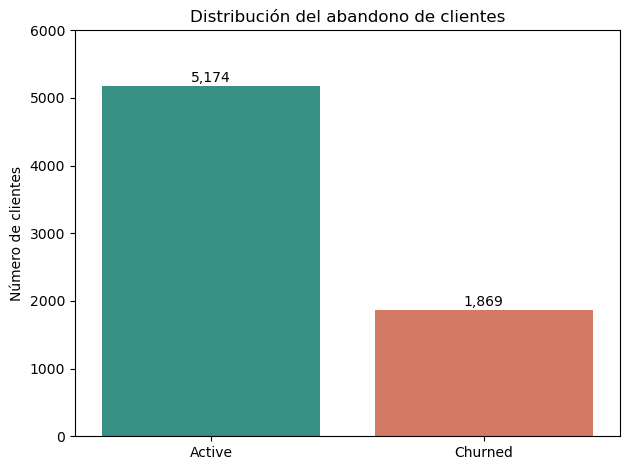

In [18]:
churn_counts = df["Churn"].value_counts().sort_index()

ax = sns.barplot(
    x=["Active", "Churned"],
    y=churn_counts.values,
    hue=["Active", "Churned"],
    palette=["#2A9D8F", "#E76F51"],
    legend=False
)

for i, count in enumerate(churn_counts.values):
    ax.text(i, count + 60, f"{count:,}", ha="center")

plt.title("Distribución del abandono de clientes")
plt.ylabel("Número de clientes")
plt.xlabel("")
plt.ylim(0, 6000)
plt.tight_layout()
plt.show()

### Hallazgo clave

La tasa general de abandono de clientes es del **26,54 %**, lo que significa que aproximadamente uno de cada cuatro clientes del conjunto de datos ha dejado de utilizar el servicio.

Esto refleja un desafío importante en cuanto a la retención de clientes y subraya la importancia de identificar qué segmentos de clientes están más asociados con el abandono.

## 11. Análisis de la tasa de abandono por segmento de clientes

Esta sección compara las tasas de abandono según el tipo de contrato, los servicios de Internet y los métodos de pago, con el fin de identificar los segmentos de clientes con mayor índice de deserción.

Las tasas de abandono se calculan dentro de cada segmento para garantizar comparaciones significativas.

### 11.1 Calcular tasa de churn

In [19]:
segments = ["Type", "InternetService", "PaymentMethod"]

for column in segments:
    churn_summary = (
        df.groupby(column)["Churn"]
        .agg(["count", "mean"])
        .rename(columns={"count": "Customers", "mean": "Churn Rate"})
        .sort_values("Churn Rate", ascending=False)
    )

    churn_summary["Churn Rate"] = (
        churn_summary["Churn Rate"] * 100
    ).round(2)

    print(f"\nChurn by {column}")
    display(churn_summary)


Churn by Type


,Customers,Churn Rate
Type,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83



Churn by InternetService


,Customers,Churn Rate
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No internet service,1526,7.40



Churn by PaymentMethod


,Customers,Churn Rate
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


### 11.2 Visualizar tasas de churn

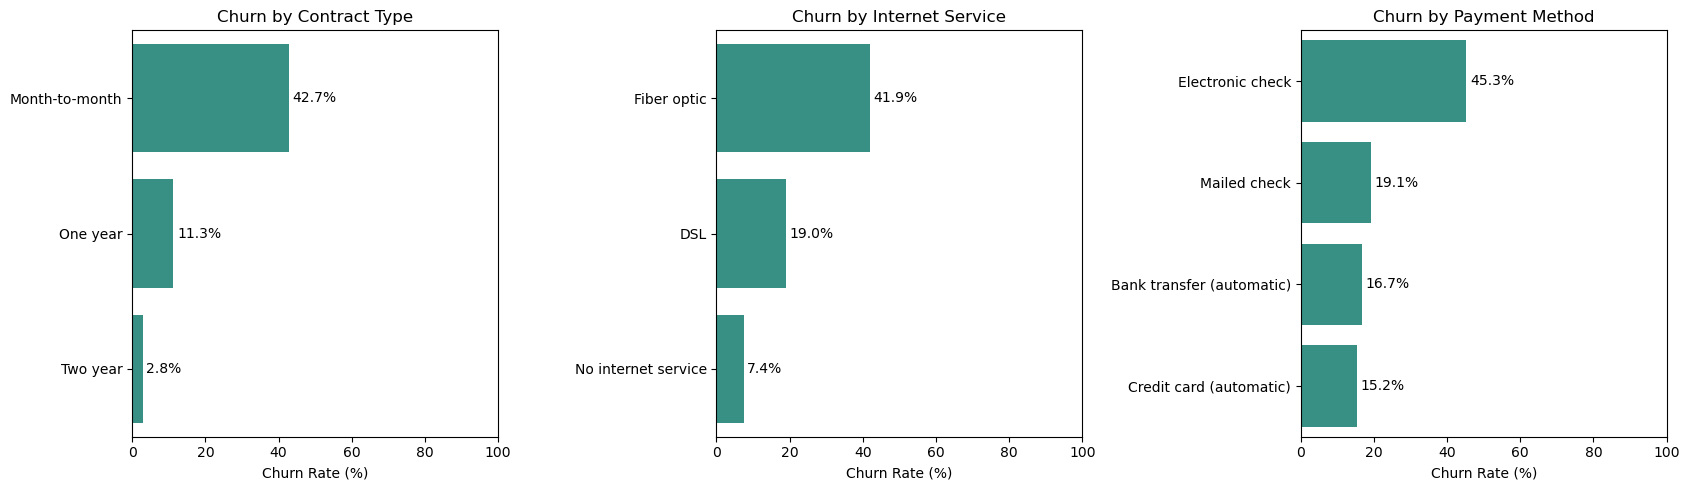

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

titles = [
    "Churn by Contract Type",
    "Churn by Internet Service",
    "Churn by Payment Method"
]

for ax, column, title in zip(axes, segments, titles):
    churn_rates = (
        df.groupby(column)["Churn"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=churn_rates.values,
        y=churn_rates.index,
        color="#2A9D8F",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Churn Rate (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)

    for i, value in enumerate(churn_rates.values):
        ax.text(value + 1, i, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()

Principales hallazgos: segmentos de clientes

Tipo de contrato: los clientes con contratos mensuales presentan la tasa de abandono más alta (42,7 %), frente al 11,3 % de los contratos anuales y el 2,8 % de los contratos bianuales.

Servicio de Internet: los clientes de fibra óptica registran una tasa de abandono del 41,9 %, cifra considerablemente superior a la de los clientes de DSL (19,0 %).

Método de pago: los usuarios que pagan mediante cheque electrónico presentan la tasa de abandono más elevada (45,3 %), en comparación con el rango del 15,2 % al 19,1 % observado en otros métodos de pago.

Estos hallazgos identifican segmentos de clientes que podrían beneficiarse de estrategias de retención específicas. No obstante, las relaciones observadas no implican una relación de causalidad.

In [22]:
# Calcular la antigüedad del cliente en meses
reference_date = pd.Timestamp("2020-02-01")

df["TenureMonths"] = (
    (reference_date.year - df["BeginDate"].dt.year) * 12
    + (reference_date.month - df["BeginDate"].dt.month)
)

# Comparar la antigüedad y las tarifas mensuales por estado de abandono(churn)
df.groupby("Churn")[["TenureMonths", "MonthlyCharges"]].agg(
    ["mean", "median"]
).round(2)

TenureMonths        MonthlyCharges       
              mean median           mean median
Churn                                          
0            37.57   38.0          61.27  64.43
1            20.48   12.0          74.44  79.65

Principales hallazgos: antigüedad del cliente y cargos mensuales

Antigüedad del cliente: los clientes que han abandonado el servicio presentan una mediana de antigüedad sustancialmente menor (12 meses) que los clientes activos (38 meses).

Cargos mensuales: los clientes que han abandonado el servicio tienen cargos mensuales promedio más elevados (74,44 $) en comparación con los clientes activos (61,27 $).

Estos patrones sugieren que los clientes con menor antigüedad y aquellos con cargos mensuales más altos podrían constituir segmentos importantes para el análisis de retención.

Los hallazgos son de carácter descriptivo y no establecen que la antigüedad o los precios sean causas directas de la pérdida de clientes.

## 12. Modelo predictivo

Se utiliza un modelo de clasificación LightGBM para identificar las características de los clientes asociados a la deserción.

El modelo se basa en el proyecto original Interconnect y emplea los hiperparámetros seleccionados previamente. Su rendimiento se evalúa mediante un conjunto de prueba estratificado (*holdout set*).

Se trata de un ejercicio de clasificación retrospectivo, no de un sistema validado de predicción de deserción en producción.

In [23]:
# Definir features y target
X = df.drop(columns=[
    "customerID",
    "BeginDate",
    "EndDate",
    "Churn"
])

y = df["Churn"]

In [24]:
# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=12345,
    stratify=y
)

# Identificar variables categóricas
categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

# Convertir columnas categóricas para LightGBM
X_train = X_train.copy()
X_test = X_test.copy()

for col in categorical_features:
    X_train[col] = X_train[col].astype("category")
    X_test[col] = X_test[col].astype("category")

# Verificar la división de datos
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Churn rate (train):", round(y_train.mean(), 4))
print("Churn rate (test):", round(y_test.mean(), 4))

Training set: (5282, 18)
Test set: (1761, 18)
Churn rate (train): 0.2654
Churn rate (test): 0.2652


## 13 Modelo inicial LightGBM
Se entrenará un modelo de clasificación LightGBM para identificar patrones asociados a la pérdida de clientes (*churn*).

El modelo utiliza datos demográficos de los clientes, información del contrato, servicios contratados y características de facturación. Se reutilizan los hiperparámetros seleccionados previamente en el proyecto original de Interconnect para mantener el análisis enfocado y computacionalmente eficiente.

In [25]:
# Entrenar LightGBM
model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.10,
    num_leaves=15,
    max_depth=5,
    random_state=12345,
    verbosity=-1
)

model.fit(X_train, y_train)

# Generar predicciones
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# Evaluar el desempeño
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")

ROC-AUC: 0.9344
Recall: 0.7388
Precision: 0.8712
F1-score: 0.7995


### Rendimiento del modelo

El modelo LightGBM inicial obtuvo los siguientes resultados en el conjunto de prueba:

ROC-AUC: 0,9344

Recall (sensibilidad): 0,7388

Precision (precisión): 0,8712

F1-score: 0,7995

Estos resultados indican un buen rendimiento de clasificación retrospectiva.

Sin embargo, las variables *TotalCharges* y *TenureMonths* podrían contener información temporal que no habría estado disponible antes de que algunos clientes cancelaran sus servicios.

Para evaluar la dependencia del modelo respecto a estas variables, en la siguiente sección se lleva a cabo una prueba de robustez.

## 14. Verificación de la robustez del modelo

Para evaluar la dependencia del modelo respecto a variables temporales potencialmente problemáticas, se excluyeron `TotalCharges` y `TenureMonths`, y se volvió a entrenar el modelo LightGBM.

El modelo ajustado obtuvo un ROC-AUC de 0,8110, frente al 0,9344 del modelo inicial.

Este modelo, más conservador, se seleccionó como resultado principal, si bien su rendimiento sigue basándose en datos retrospectivos.

In [26]:
# Eliminar características temporales potencialmente problemáticas.
X_train_check = X_train.drop(
    columns=["TotalCharges", "TenureMonths"]
)

X_test_check = X_test.drop(
    columns=["TotalCharges", "TenureMonths"]
)

# Entrenar el modelo con las características restantes
model_check = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.10,
    num_leaves=15,
    max_depth=5,
    random_state=12345,
    verbosity=-1
)

model_check.fit(X_train_check, y_train)

# Evaluar el rendimiento del modelo ajustado
y_pred_check = model_check.predict(X_test_check)
y_proba_check = model_check.predict_proba(X_test_check)[:, 1]

print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_check):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_check):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_check):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_check):.4f}")

ROC-AUC: 0.8110
Recall: 0.4989
Precision: 0.5825
F1-score: 0.5375


### Resultados de la prueba de robustez

Tras excluir `TotalCharges` y `TenureMonths`, el modelo ajustado obtuvo los siguientes resultados:

- **ROC-AUC:** 0,8110
- **Recall (Sensibilidad):** 0,4989
- **Precisión:** 0,5825
- **Puntuación F1:** 0,5375

La reducción en el rendimiento indica que el modelo inicial dependía en gran medida de las variables excluidas.

Aunque el modelo ajustado presenta un rendimiento inferior, reduce la dependencia de información temporal potencialmente problemática.

Se selecciona el modelo ajustado como resultado principal para un análisis retrospectivo más conservador de la clasificación de abandono (*churn*).

No obstante, sería necesaria una evaluación basada en el tiempo para determinar el rendimiento predictivo futuro.

## 15. Importancia de las características

Se analiza la importancia de las características para identificar las variables que LightGBM utiliza con mayor frecuencia para distinguir entre clientes que han abandonado el servicio y clientes activos.

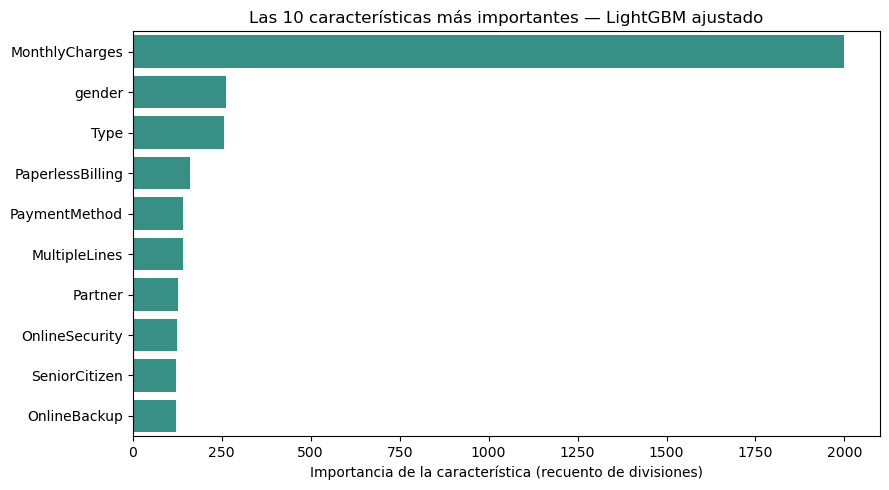

In [27]:
# Extraer la importancia de las características
importance = pd.Series(
    model_check.feature_importances_,
    index=X_train_check.columns
).sort_values(ascending=False).head(10)

# Visualizar el top 10 características más importantes
plt.figure(figsize=(9, 5))

sns.barplot(
    x=importance.values,
    y=importance.index,
    color="#2A9D8F"
)

plt.title("Las 10 características más importantes — LightGBM ajustado")
plt.xlabel("Importancia de la característica (recuento de divisiones)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Interpretación de la importancia de las variables

`MonthlyCharges` es, con diferencia, la variable utilizada con mayor frecuencia en el modelo LightGBM ajustado, seguida de `gender` y `Type`.

Otras variables, como `PaperlessBilling`, `PaymentMethod` y `MultipleLines`, contribuyen a las decisiones de clasificación del modelo, pero presentan un número de divisiones sustancialmente menor.

Estos resultados sugieren que las características de facturación y la información sobre el contrato desempeñan un papel importante en las predicciones del modelo.

No obstante, la importancia de las variables basada en el número de divisiones no establece causalidad, no indica la dirección del efecto de una variable ni justifica la toma de decisiones sobre la retención de clientes basándose en características demográficas.

## 16. Recomendaciones empresariales y conclusión

Hallazgos clave

El análisis identificó varios segmentos de clientes asociados a una mayor tasa de abandono (*churn*):

- Tipo de contrato: Los clientes con contratos mensuales presentan una tasa de abandono del 42,7%, frente al 11,3% de los contratos anuales y el 2,8% de los contratos bianuales.

- Servicio de Internet: Los clientes de fibra óptica muestran una tasa de abandono del 41,9%, lo que sugiere una oportunidad para investigar su experiencia con el servicio.

- Método de pago: Los usuarios que pagan mediante cheque electrónico registran la tasa de abandono más alta (45,3%).

- Características del cliente: Por lo general, los clientes que abandonan el servicio tienen una menor antigüedad y cargos mensuales más elevados.

Resultados del modelado predictivo

El modelo inicial LightGBM alcanzó un valor ROC-AUC de 0,9344. Sin embargo, una prueba de robustez reveló que su rendimiento dependía en gran medida de la antigüedad y los cargos acumulados, variables que presentan posibles limitaciones relacionadas con la información temporal.

Tras excluir estas características, el modelo ajustado obtuvo los siguientes resultados:

| Metric | Initial Model | Adjusted Model |
|:---|---:|---:|
| ROC-AUC | 0.9344 | 0.8110 |
| Recall | 0.7388 | 0.4989 |
| Precision | 0.8712 | 0.5825 |
| F1-score | 0.7995 | 0.5375 |

Se seleccionó el modelo ajustado como resultado principal para ofrecer una evaluación más conservadora del rendimiento en la clasificación retrospectiva del abandono de clientes.

Recomendaciones empresariales

1. Priorizar a los clientes con contratos mensuales: Evaluar incentivos de fidelización específicos y ofertas de contratos a más largo plazo.

2. Investigar la experiencia de los clientes de fibra óptica: Analizar la calidad del servicio, las interacciones con el soporte técnico y los comentarios de los clientes para identificar posibles fuentes de insatisfacción.

3. Revisar la experiencia de pago: Investigar si los usuarios de cheques electrónicos enfrentan dificultades de facturación y evaluar oportunidades para fomentar los pagos automáticos.

4. Desarrollar iniciativas de retención temprana: Considerar estrategias de incorporación (*onboarding*) y de interacción proactiva para los clientes más recientes, especialmente aquellos con cargos mensuales más altos.

Limitaciones

El conjunto de datos no incluye mediciones directas de satisfacción del cliente, reclamaciones ni indicadores de calidad del servicio. Por consiguiente, el análisis identifica asociaciones con el abandono, pero no causas confirmadas de insatisfacción del cliente. Ambos modelos se evaluaron utilizando registros históricos de clientes y una división aleatoria de los datos para entrenamiento y prueba. Aunque el modelo ajustado excluye variables temporales potencialmente problemáticas, su rendimiento no ha sido validado para predecir futuras cancelaciones por parte de los clientes.

Conclusión

Este proyecto demuestra cómo el análisis de clientes y el aprendizaje automático pueden respaldar las estrategias de retención mediante la identificación de segmentos de clientes con una alta probabilidad de abandono, la evaluación de patrones predictivos y la transformación de los hallazgos analíticos en recomendaciones empresariales aplicables.